# WHATEVER YOU DO - DOOOOO NOTTTTTTTTTT restart kernal and rerun all cells, cells 8 & 9 take an hour to run

## 1. Configuration and imports

In [21]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter
from matplotlib.colors import LogNorm
import plotly.graph_objects as go
from pyproj import Transformer


# working_notebooks/ERT/ ; use Jupyter with this directory as the current working directory.
NOTEBOOK_DIR = Path.cwd().resolve()
DATA_DIR = (NOTEBOOK_DIR / "../../Data").resolve()
PROCESSING_DIR = NOTEBOOK_DIR / "ERT_outputs"
INVERSION_DIR = PROCESSING_DIR / "DipoleDipole_Inversions"
INVERSION_DIR.mkdir(parents=True, exist_ok=True)

PROCESSED_FILES = {
    1: PROCESSING_DIR / "dd1_processed.csv",
    2: PROCESSING_DIR / "dd2_processed.csv",
}
DGPS_FILES = {
    1: PROCESSING_DIR / "DGPS_Line1_aligned.csv",
    2: PROCESSING_DIR / "DGPS_Line2_aligned.csv",
}
ORIGINAL_DAT_FILES = {
    1: DATA_DIR / "ERT data" / "DipoleDipole_1-2023-03-07-214954.dat",
    2: DATA_DIR / "ERT data" / "DipoleDipole_2-2023-03-07-214927.dat",
}

N_ELECTRODES = 64
SPACING_M = 1.5
RELATIVE_ERROR = 0.05          # provisional 5% relative noise estimate
MEDIAN_FLOOR_FRACTION = 0.01   # provisional 1% of median |R| floor
CELL_SIZE_M = 0.75            # smallest mesh cell; half nominal electrode spacing
MAX_ITERATIONS = 20
RUN_LINE1 = True               # start with Line 1; inspect before enabling Line 2
RUN_LINE2 = True
SAVE_FIGURES = False

required = [*PROCESSED_FILES.values(), *DGPS_FILES.values(), *ORIGINAL_DAT_FILES.values()]
missing = [str(f) for f in required if not f.is_file()]
if missing:
    raise FileNotFoundError("Missing files (run preprocessing first; verify paths):\n" + "\n".join(missing))

print("Working directory:", NOTEBOOK_DIR)
print("Inversion output:", INVERSION_DIR)
print("Line 1 enabled:", RUN_LINE1, "| Line 2 enabled:", RUN_LINE2)

def save_plot(fig, filename):
    if SAVE_FIGURES:
        fig.savefig(INVERSION_DIR / filename, dpi=300, bbox_inches="tight")


FileNotFoundError: Missing files (run preprocessing first; verify paths):
C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\ERT_outputs\dd1_processed.csv
C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\ERT_outputs\dd2_processed.csv
C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\ERT_outputs\DGPS_Line1_aligned.csv
C:\Users\molly\work\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\working_notebooks\ERT\ERT_outputs\DGPS_Line2_aligned.csv

## 2. Load only dipole–dipole datasets and confirm ABEM units

In [2]:
def read_dat_metadata(filename):
    """RES2DINV general-array header: 0=apparent resistivity, 1=resistance."""
    lines = filename.read_text(encoding="utf-8", errors="replace").splitlines()
    if len(lines) < 10:
        raise ValueError(f"Not a recognized ABEM .dat file: {filename}")
    try:
        return {
            "spacing_m": float(lines[1].strip()),
            "array_code": int(lines[2].strip()),
            "sub_array_code": int(lines[3].strip()),
            "measurement_type": int(lines[5].strip()),
            "n_measurements": int(lines[6].strip()),
            "x_location_type": int(lines[7].strip()),
        }
    except (ValueError, IndexError) as exc:
        raise ValueError(f"ABEM header not recognized: {filename}") from exc


def load_line(line):
    df = pd.read_csv(PROCESSED_FILES[line])
    profile = pd.read_csv(DGPS_FILES[line]).sort_values("electrode").reset_index(drop=True)
    metadata = read_dat_metadata(ORIGINAL_DAT_FILES[line])
    required_df = ["A_x", "B_x", "M_x", "N_x", "resistance", "K", "apparent_resistivity"]
    required_profile = ["electrode", "distance_m", "elevation_m", "Name"]
    for required, table, name in [(required_df, df, "measurements"),
                                   (required_profile, profile, "DGPS")]:
        absent = sorted(set(required) - set(table.columns))
        if absent:
            raise ValueError(f"Line {line} {name} missing columns: {absent}")
    if metadata["measurement_type"] != 1:
        raise ValueError(f"Line {line}: ABEM file is not tagged as resistance (header 1). Stop.")
    if metadata["array_code"] != 11:
        raise ValueError(f"Line {line}: expected RES2DINV general array code 11. Stop.")
    if not np.isclose(metadata["spacing_m"], SPACING_M):
        raise ValueError(f"Line {line}: spacing mismatch, header is {metadata['spacing_m']} m.")
    if len(df) != metadata["n_measurements"]:
        raise ValueError(f"Line {line}: processed rows do not match ABEM .dat rows.")
    if len(profile) != N_ELECTRODES or not np.array_equal(
        profile["electrode"].to_numpy(dtype=int), np.arange(1, N_ELECTRODES + 1)
    ):
        raise ValueError(f"Line {line}: expected all {N_ELECTRODES} DGPS electrodes exactly once.")
    expected_first, expected_last = ("ert64", "ert1") if line == 1 else ("2ert64", "2ert1")
    if str(profile.iloc[0]["Name"]) != expected_first or str(profile.iloc[-1]["Name"]) != expected_last:
        raise ValueError(f"Line {line}: DGPS electrode order differs from established reversed mapping.")
    expected_x = (profile["electrode"].to_numpy() - 1) * SPACING_M
    if not np.allclose(profile["distance_m"], expected_x, atol=0.01):
        raise ValueError(f"Line {line}: DGPS profile distances differ from 1.5 m nominal spacing.")
    if metadata["x_location_type"] == 2:
        print(f"CAUTION Line {line}: ABEM x values represent surface distance."
              " Nominal 1.5 m x positions are being used as horizontal distances in the 2D"
              " inversion; inspect actual DGPS horizontal spacing before geological interpretation.")
    elif metadata["x_location_type"] != 1:
        raise ValueError(f"Line {line}: unexpected x-location type {metadata['x_location_type']}")
    return df, profile, metadata

raw_data = {}
profiles = {}
headers = {}
for line in (1, 2):
    raw_data[line], profiles[line], headers[line] = load_line(line)
    print(f"Line {line}: {len(raw_data[line])} ABMN records, "
          f"{len(profiles[line])} surveyed electrodes, header: {headers[line]}")


CAUTION Line 1: ABEM x values represent surface distance. Nominal 1.5 m x positions are being used as horizontal distances in the 2D inversion; inspect actual DGPS horizontal spacing before geological interpretation.
Line 1: 1980 ABMN records, 64 surveyed electrodes, header: {'spacing_m': 1.5, 'array_code': 11, 'sub_array_code': 3, 'measurement_type': 1, 'n_measurements': 1980, 'x_location_type': 2}
CAUTION Line 2: ABEM x values represent surface distance. Nominal 1.5 m x positions are being used as horizontal distances in the 2D inversion; inspect actual DGPS horizontal spacing before geological interpretation.
Line 2: 1980 ABMN records, 64 surveyed electrodes, header: {'spacing_m': 1.5, 'array_code': 11, 'sub_array_code': 3, 'measurement_type': 1, 'n_measurements': 1980, 'x_location_type': 2}


## 3. Review QC before solving any inverse problem

A row is excluded only for non-finite/non-positive resistances or geometric factors, invalid coordinates, or an explicitly entered row index. **No percentile-based outlier deletion** is performed automatically. Inspect unexpected high/low readings before deciding whether to remove them.

Line 1: 1980/1980 accepted; 0 excluded
  Apparent resistivity percentiles [1, 25, 50, 75, 99] Ω·m: [19.61 30.12 38.36 46.77 73.25]
Line 2: 1980/1980 accepted; 0 excluded
  Apparent resistivity percentiles [1, 25, 50, 75, 99] Ω·m: [ 17.99  29.26  47.98  73.28 138.12]


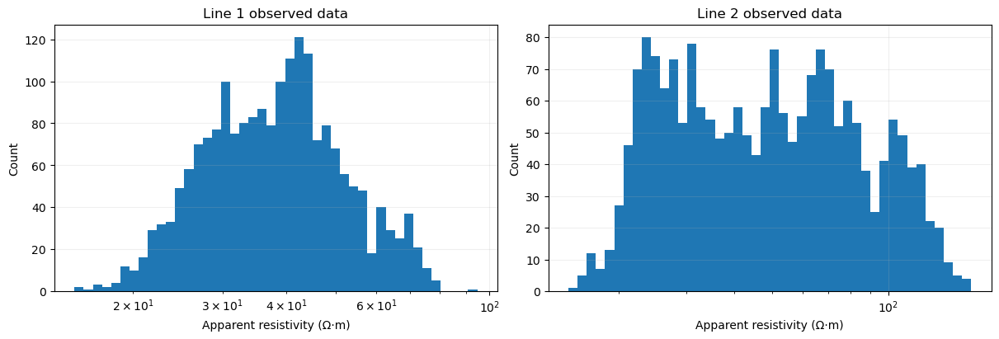

In [3]:
# Optional zero-based CSV indices of confirmed bad measurements; leave empty initially.
EXCLUDE_ROWS = {1: [], 2: []}

def quality_control(df, line):
    df = df.copy().reset_index(drop=True)
    df["original_row"] = np.arange(len(df))
    pos = df["resistance"].to_numpy(dtype=float)
    rho = df["apparent_resistivity"].to_numpy(dtype=float)
    K = df["K"].to_numpy(dtype=float)
    xcols = [df[f"{electrode}_x"].to_numpy(dtype=float) for electrode in "ABMN"]
    valid = np.isfinite(pos) & (pos > 0) & np.isfinite(rho) & (rho > 0)
    valid &= np.isfinite(K) & (K > 0)
    for xs in xcols:
        valid &= np.isfinite(xs) & (xs >= -1e-6) & (xs <= 63 * SPACING_M + 1e-6)
        valid &= np.isclose(xs / SPACING_M, np.round(xs / SPACING_M), atol=1e-5)
    # Resistivity conversion consistency check from original processing.
    assert np.allclose(rho[valid], (K * pos)[valid], rtol=1e-5, atol=1e-7)
    if EXCLUDE_ROWS[line]:
        valid &= ~np.isin(df["original_row"].to_numpy(), EXCLUDE_ROWS[line])
    df["use_for_inversion"] = valid
    accepted = df.loc[valid].copy()
    if len(accepted) < 100:
        raise ValueError(f"Line {line}: too few usable measurements ({len(accepted)})")
    print(f"Line {line}: {len(accepted)}/{len(df)} accepted; {len(df)-len(accepted)} excluded")
    print("  Apparent resistivity percentiles [1, 25, 50, 75, 99] Ω·m:",
          np.round(np.percentile(accepted["apparent_resistivity"], [1,25,50,75,99]), 2))
    if (len(df) - len(accepted)) > 0:
        display(df.loc[~valid, ["original_row", "A_x", "B_x", "M_x", "N_x",
                               "resistance", "apparent_resistivity"]].head(20))
    df.to_csv(INVERSION_DIR / f"Line{line}_QC_all_rows.csv", index=False)
    return accepted

accepted = {line: quality_control(raw_data[line], line) for line in (1, 2)}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for i, line in enumerate((1, 2)):
    vals = accepted[line]["apparent_resistivity"].to_numpy()
    axes[i].hist(vals, bins=np.geomspace(np.min(vals), np.max(vals), 45))
    axes[i].set_xscale("log")
    axes[i].set(xlabel="Apparent resistivity (Ω·m)", ylabel="Count", title=f"Line {line} observed data")
    axes[i].grid(alpha=0.2)
save_plot(fig, "BothLines_QC_histograms.png")
plt.show()


## 4. Construct measured electrode locations (A/B/M/N) and survey geometry

Interpolate each electrode’s **relative DGPS height** at its nominal x location; do **not** substitute pseudosection point depths. Absolute ellipsoidal heights are shifted by a constant to keep solver coordinates numerically compact. SimPEG internally groups AB source dipoles: the `output_sorting=True` index must also reorder observed resistance and uncertainties.

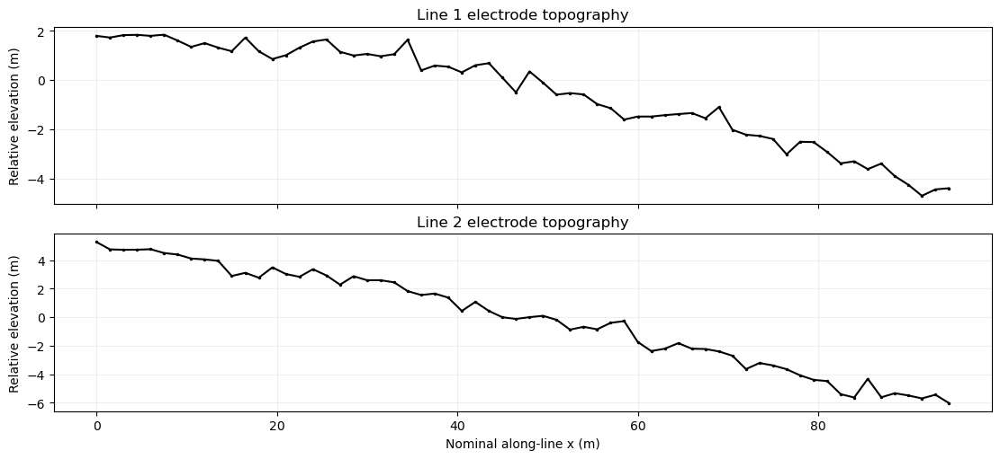

In [4]:
def make_electrode_array(df, profile, electrode, datum):
    x = df[f"{electrode}_x"].to_numpy(dtype=float)
    # ABEM x=0 corresponds to the DGPS point labelled ert64 / 2ert64.
    z = np.interp(x, profile["distance_m"].to_numpy(dtype=float),
                  profile["elevation_m"].to_numpy(dtype=float)) - datum
    return np.c_[x, z]


def setup_line_geometry(line):
    df, profile = accepted[line], profiles[line]
    datum = float(np.median(profile["elevation_m"]))  # ellipsoidal reference, m
    topo = np.c_[profile["distance_m"].to_numpy(dtype=float),
                 profile["elevation_m"].to_numpy(dtype=float) - datum]
    coords = {p: make_electrode_array(df, profile, p, datum) for p in "ABMN"}
    # Check all points correspond to electrodes and no A/B or M/N is coincident.
    for p in "ABMN":
        if not np.all(np.isfinite(coords[p])):
            raise ValueError(f"Line {line}: non-finite {p} coordinates")
    if np.any(np.linalg.norm(coords["A"] - coords["B"], axis=1) < 0.1) or \
       np.any(np.linalg.norm(coords["M"] - coords["N"], axis=1) < 0.1):
        raise ValueError(f"Line {line}: coincident source or receiver electrodes")
    return {"df": df, "topo": topo, "coords": coords, "datum": datum}

geometry = {line: setup_line_geometry(line) for line in (1, 2)}

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, constrained_layout=True)
for ax, line in zip(axes, (1, 2)):
    ax.plot(*geometry[line]["topo"].T, "k.-", ms=3)
    ax.set(ylabel="Relative elevation (m)", title=f"Line {line} electrode topography")
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Nominal along-line x (m)")
save_plot(fig, "BothLines_DGPS_geometry.png")
plt.show()


## 5. Import SimPEG

Run this cell once to confirm the inversion dependencies. On a Jupyter environment without SimPEG, install it **in your notebook kernel** using `%pip install simpeg discretize pymatsolver` in a separate cell, then restart the kernel and run the notebook again. The package is `simpeg` (lowercase) for current releases.

In [5]:
try:
    import simpeg
    from simpeg import (maps, data, data_misfit, regularization,
                        optimization, inverse_problem, inversion, directives)
    from simpeg.electromagnetics.static import resistivity as dc
    from simpeg.electromagnetics.static.utils import generate_survey_from_abmn_locations
    from discretize import TreeMesh
    from discretize.utils import active_from_xyz
except ImportError as exc:
    raise ImportError("Install SimPEG in this kernel: %pip install simpeg discretize pymatsolver; "
                      "then restart the kernel and rerun.") from exc

print("SimPEG version:", simpeg.__version__)


SimPEG version: 0.24.0


## 6. Survey objects and uncertainty model

The inverted datum is the **measured resistance `V/I` in Ω** (entered as SimPEG `volt`, i.e. a voltage normalized to unit injection current). The original flat-earth geometric factor is used for **display/QC only**, not passed to the forward model. A constant error floor below is an assumption; where reciprocal errors are available, replace it with data-supported standard deviations.

In [6]:
def build_simpeg_data(geom, line):
    df = geom["df"]
    xyz = geom["coords"]
    survey, sort_index = generate_survey_from_abmn_locations(
        locations_a=xyz["A"], locations_b=xyz["B"],
        locations_m=xyz["M"], locations_n=xyz["N"],
        data_type="volt", output_sorting=True,
    )
    # Sort the corresponding observations to SimPEG source/receiver ordering.
    ordered = df.iloc[sort_index].copy().reset_index(drop=True)
    r = ordered["resistance"].to_numpy(dtype=float)
    floor = MEDIAN_FLOOR_FRACTION * float(np.median(np.abs(r)))
    std = RELATIVE_ERROR * np.abs(r) + floor
    obs = data.Data(survey, dobs=r)
    obs.standard_deviation = std
    if len(r) != survey.nD:
        raise ValueError(f"Line {line}: sorted survey/data length mismatch")
    print(f"Line {line}: {survey.nD} resistance measurements; "
          f"assumed noise = {100 * RELATIVE_ERROR:.0f}% |R| + {floor:.4g} Ω")
    return {"survey": survey, "obs": obs, "ordered": ordered, "std": std}

surveys = {line: build_simpeg_data(geometry[line], line) for line in (1, 2)}


C:\Users\molly\AppData\Local\Temp\ipykernel_30212\1311093486.py:4: UserWarning: Ordering of ABMN locations changed when generating survey. Associated data vectors will need sorting. Set output_sorting to True for sorting indices.
  survey, sort_index = generate_survey_from_abmn_locations(


Line 1: 1980 resistance measurements; assumed noise = 5% |R| + 0.0003125 Ω
Line 2: 1980 resistance measurements; assumed noise = 5% |R| + 0.0003853 Ω


## 7. Create a topographic TreeMesh and smooth inverse problem

This is a **2.5D** formulation: subsurface properties vary in the survey plane, but current flow is modeled in 3D. The domain extends beyond the 94.5 m electrode spread to mitigate artificial model boundaries. Constant end elevations beyond the DGPS endpoints are **extrapolated assumptions**. Start with 0.75 m minimum cells and consider a mesh-refinement convergence test later.

In [11]:
def make_mesh_and_active(geom, survey):
    topo = geom["topo"]
    dh = CELL_SIZE_M
    nx, nz = 512, 256     # 384 m across and 192 m vertical for dh=0.75
    dom_x, dom_z = nx * dh, nz * dh
    center_x = 0.5 * (topo[:, 0].min() + topo[:, 0].max())
    # Keep ~10 m of air above the highest DGPS electrode.
    x0 = center_x - dom_x / 2
    z0 = float(np.max(topo[:, 1]) + 10 - dom_z)
    mesh = TreeMesh([[(dh, nx)], [(dh, nz)]], x0=[x0, z0], diagonal_balance=True)

    topo_extended = np.vstack([
        [x0 + dh, topo[0, 1]],
        topo,
        [x0 + dom_x - dh, topo[-1, 1]],
    ])
    mesh.refine_surface(topo_extended, padding_cells_by_level=[0, 0, 4, 4], finalize=False)
    # Refine around all surface electrodes as in the SimPEG tutorial.
    unique_els = survey.unique_electrode_locations
    mesh.refine_points(unique_els, padding_cells_by_level=[1, 2, 3, 3], finalize=False)
    mesh.finalize()
    active_cells = active_from_xyz(mesh, topo_extended)
    if int(active_cells.sum()) < 100:
        raise RuntimeError("Very few active mesh cells; inspect domain and topography")
    # Electrode positions must be on the discretized topographic surface.
    survey.drape_electrodes_on_topography(mesh, active_cells)
    return mesh, active_cells, topo_extended


def make_inverse_problem(geom, prepared, line):
    survey, obs = prepared["survey"], prepared["obs"]
    mesh, active, topo = make_mesh_and_active(geom, survey)
    n_active = int(active.sum())
    background_rho = float(np.median(prepared["ordered"]["apparent_resistivity"]))
    m0 = np.log(1.0 / background_rho) * np.ones(n_active)  # log conductivity, S/m
    mapping = maps.InjectActiveCells(mesh, active, 1e-8) * maps.ExpMap(nP=n_active)

    sim = dc.simulation_2d.Simulation2DNodal(
        mesh, survey=survey, sigmaMap=mapping, storeJ=True
    )
    misfit = data_misfit.L2DataMisfit(simulation=sim, data=obs)
    reg = regularization.WeightedLeastSquares(
        mesh, active_cells=active, alpha_s=CELL_SIZE_M**-2,
        alpha_x=1.0, alpha_y=1.0, reference_model=m0.copy(),
        reference_model_in_smooth=False,
    )
    opt = optimization.InexactGaussNewton(
    maxIter=MAX_ITERATIONS,
    maxIterLS=20,
    maxIterCG=20,
    tolCG=1e-3,
)
    problem = inverse_problem.BaseInvProblem(misfit, reg, opt)
    instruction_set = [
        directives.UpdateSensitivityWeights(every_iteration=True, threshold_value=1e-2),
        directives.UpdatePreconditioner(update_every_iteration=True),
        directives.BetaEstimate_ByEig(beta0_ratio=10),
        directives.BetaSchedule(coolingFactor=2.0, coolingRate=2),
        directives.TargetMisfit(chifact=1.0),
    ]
    engine = inversion.BaseInversion(problem, directiveList=instruction_set)
    print(f"Line {line}: mesh {mesh.n_cells} cells; {n_active} active cells; "
          f"starting resistivity = {background_rho:.2f} Ω·m")
    return dict(mesh=mesh, active=active, topo=topo, sim=sim, obs=obs,
                inverse=engine, problem=problem, m0=m0, background_rho=background_rho)


## 8. Run **Line 1** inversion

This is the computationally expensive part. It fits all accepted resistance measurements, not interpolated color pixels. Inspect the convergence log (`phi_d`, `phi_m`, `beta`) and the exported diagnostics before switching on the second line.

In [12]:
results = {}

def solve_line(line):
    fitted = make_inverse_problem(geometry[line], surveys[line], line)
    recovered = fitted["inverse"].run(fitted["m0"])
    fitted["m_recovered"] = recovered
    fitted["predicted_R"] = fitted["sim"].dpred(recovered)
    results[line] = fitted
    return fitted

if RUN_LINE1:
    print("\n--- Inverting Dipole–Dipole Line 1 ---")
    solve_line(1)
else:
    print("Line 1 disabled: set RUN_LINE1=True in Cell 3 to run")



--- Inverting Dipole–Dipole Line 1 ---
Line 1: mesh 3266 cells; 1639 active cells; starting resistivity = 38.36 Ω·m

Running inversion with SimPEG v0.24.0

                        simpeg.InvProblem is setting bfgsH0 to the inverse of the eval2Deriv.
                        ***Done using same Solver, and solver_opts as the Simulation2DNodal problem***
                        


C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\base\pde_simulation.py:490: DefaultSolverWarning: Using the default solver: Pardiso. 

If you would like to suppress this notification, add 
warnings.filterwarnings('ignore', simpeg.utils.solver_utils.DefaultSolverWarning)
 to your script.
  return get_default_solver(warn=True)
C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\pymatsolver\solvers.py:415: FutureWarning: In Future pymatsolver v0.4.0, passing a vector of shape (n, 1) to the solve method will return an array with shape (n, 1), instead of always returning a flattened array. This is to be consistent with numpy.linalg.solve broadcasting.
  return self.solve(val)


model has any nan: 0
============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
x0 has any nan: 0
   0  3.37e+03  1.90e+05  0.00e+00  1.90e+05    6.12e+04      0              
   1  3.37e+03  5.69e+04  1.16e+01  9.60e+04    1.55e+04      0              
   2  1.69e+03  5.42e+04  1.13e+01  7.32e+04    5.41e+03      0              
   3  1.69e+03  4.13e+04  1.80e+01  7.17e+04    1.48e+03      0              
   4  8.43e+02  4.38e+04  1.60e+01  5.73e+04    6.08e+03      0              
   5  8.43e+02  2.97e+04  3.04e+01  5.54e+04    1.78e+03      0              
   6  4.22e+02  3.26e+04  2.53e+01  4.32e+04    4.57e+03      0              
   7  4.22e+02  2.20e+04  4.62e+01  4.15e+04    1.49e+03      0              
   8  2.11e+02  2.36e+04  3.88e+01  3.18e+04    3.42e+03      0              
   9  2.11e+02  1.56e+04

## 9. Plot and export recovered models / data fits

The model shows recovered **subsurface resistivity** (Ω·m), not apparent-resistivity pseudosection values. The residual figure compares observed and predicted V/I. The normalized residual `(observed - predicted)/σ` diagnoses whether a small subset of readings dominates the fit.

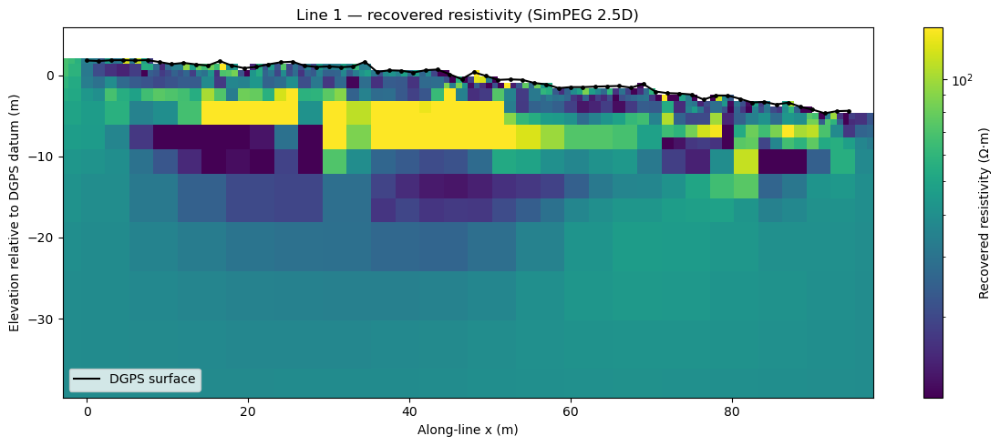

Line 1: normalized residual RMS=1.705; chi²/N=2.908 (based on assumed errors)


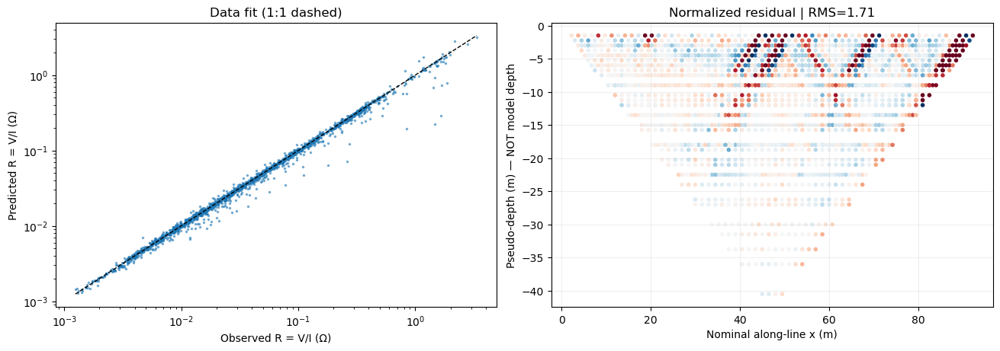

In [13]:
def report_line(line):
    out = results[line]
    mesh, active = out["mesh"], out["active"]
    rho_active = 1.0 / np.exp(out["m_recovered"])
    fill_map = maps.InjectActiveCells(mesh, active, np.nan)
    rho_full = fill_map * rho_active
    x = geometry[line]["topo"][:, 0]
    z = geometry[line]["topo"][:, 1]
    p02, p98 = np.percentile(rho_active, [2, 98])
    norm = LogNorm(vmin=max(float(p02), 1e-4), vmax=max(float(p98), float(p02) * 1.01))

    fig, ax = plt.subplots(figsize=(12, 5))
    mesh.plot_image(rho_full, normal="Y", ax=ax, grid=False,
                    pcolor_opts={"norm": norm, "cmap": "viridis"})
    ax.plot(x, z, "k", lw=1.5, label="DGPS surface")
    ax.scatter(x, z, c="k", s=6)
    ax.set(xlabel="Along-line x (m)", ylabel="Elevation relative to DGPS datum (m)",
           title=f"Line {line} — recovered resistivity (SimPEG 2.5D)",
           xlim=(-3, 97.5), ylim=(np.min(z)-35, np.max(z)+4))
    ax.legend(loc="lower left")
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax,
                 label="Recovered resistivity (Ω·m)")
    fig.tight_layout()
    save_plot(fig, f"Line{line}_inverted_resistivity.png")
    plt.show()

    # Use the original (flat-earth) K consistently on observed and predicted R
    # for comparing apparent resistivity; topography is already in the FORWARD physics.
    df = surveys[line]["ordered"].copy()
    r_obs = out["obs"].dobs
    r_pred = out["predicted_R"]
    std = out["obs"].standard_deviation
    residual = (r_obs - r_pred) / std
    chi2_n = float(np.mean(residual**2))
    print(f"Line {line}: normalized residual RMS={np.sqrt(chi2_n):.3f}; "
          f"chi²/N={chi2_n:.3f} (based on assumed errors)")
    df["predicted_resistance"] = r_pred
    df["normalized_residual"] = residual
    df["resistance_sigma"] = std
    df["predicted_rho_a_flat_K"] = r_pred * df["K"].to_numpy()
    df.to_csv(INVERSION_DIR / f"Line{line}_data_fit.csv", index=False)

    fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
    lo = min(np.min(r_obs), np.min(r_pred))
    hi = max(np.max(r_obs), np.max(r_pred))
    positive = (r_obs > 0) & (r_pred > 0)
    if np.any(positive):
        axs[0].loglog(r_obs[positive], r_pred[positive], ".", markersize=3, alpha=0.5)
        axs[0].plot([lo, hi], [lo, hi], "k--", lw=1)
        axs[0].set(xlabel="Observed R = V/I (Ω)", ylabel="Predicted R = V/I (Ω)",
                   title="Data fit (1:1 dashed)")
    else:
        axs[0].plot(r_obs, r_pred, ".")
    axs[1].scatter(df["distance_m"], -df["pseudo_depth_m"], c=residual,
                   cmap="RdBu_r", vmin=-4, vmax=4, s=9)
    axs[1].set(xlabel="Nominal along-line x (m)", ylabel="Pseudo-depth (m) — NOT model depth",
               title=f"Normalized residual | RMS={np.sqrt(chi2_n):.2f}")
    axs[1].grid(alpha=0.2)
    save_plot(fig, f"Line{line}_data_fit_and_residuals.png")
    plt.show()

    # Model array aligns with active cell centers only; preserve z and x for GIS/plotting.
    cc = mesh.cell_centers[active]
    model_table = pd.DataFrame({"x_m": cc[:, 0], "z_relative_m": cc[:, 1],
                                "resistivity_ohm_m": rho_active,
                                "conductivity_S_m": np.exp(out["m_recovered"])})
    model_table.to_csv(INVERSION_DIR / f"Line{line}_recovered_model_cells.csv", index=False)
    summary = {"line": line, "n_data": len(df), "n_active_cells": len(rho_active),
               "median_input_rho_a": out["background_rho"],
               "normalized_residual_rms": float(np.sqrt(chi2_n)),
               "chi2_per_datum": chi2_n,
               "ellipsoidal_height_reference_m": geometry[line]["datum"],
               "relative_error": RELATIVE_ERROR,
               "floor_fraction_of_median_resistance": MEDIAN_FLOOR_FRACTION}
    (INVERSION_DIR / f"Line{line}_inversion_summary.json").write_text(json.dumps(summary, indent=2))
    return summary

summaries = {}
for line in (1, 2):
    if line in results:
        summaries[line] = report_line(line)


## 10. Run **Line 2** independently

After inspecting Line 1 and verifying the dipole/dgps alignment, switch `RUN_LINE2 = True` in the settings cell, then run this cell and the report cell again. It uses a different DGPS surface, starting model, mesh and inversion result.


--- Inverting Dipole–Dipole Line 2 ---
Line 2: mesh 3410 cells; 2052 active cells; starting resistivity = 47.98 Ω·m

Running inversion with SimPEG v0.24.0

                        simpeg.InvProblem is setting bfgsH0 to the inverse of the eval2Deriv.
                        ***Done using same Solver, and solver_opts as the Simulation2DNodal problem***
                        


C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\base\pde_simulation.py:490: DefaultSolverWarning: Using the default solver: Pardiso. 

If you would like to suppress this notification, add 
warnings.filterwarnings('ignore', simpeg.utils.solver_utils.DefaultSolverWarning)
 to your script.
  return get_default_solver(warn=True)
C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\electromagnetics\static\resistivity\simulation_2d.py:768: RuntimeWarning: invalid value encountered in divide
  r_hat = r_vec / r[:, None]
C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\simpeg\electromagnetics\static\resistivity\simulation_2d.py:795: RuntimeWarning: invalid value encountered in divide
  alpha[not_top] = (ky * k1e(ky * r) / k0e(ky * r) * r_dot_n)[not_top]
C:\Users\molly\anaconda3\envs\gpgn-318\Lib\site-packages\pymatsolver\solvers.py:415: FutureWarning: In Future pymatsolver v0.4.0, passing a vector of shape (n, 1) to the solve method will return an array with 

model has any nan: 0
============================ Inexact Gauss Newton ============================
  #     beta     phi_d     phi_m       f      |proj(x-g)-x|  LS    Comment   
-----------------------------------------------------------------------------
x0 has any nan: 0
   0  7.23e+03  3.90e+05  0.00e+00  3.90e+05    1.24e+05      0              
   1  7.23e+03  1.37e+05  8.14e+00  1.96e+05    5.72e+04      0              
   2  3.61e+03  8.88e+04  1.36e+01  1.38e+05    5.88e+03      0   Skip BFGS  
   3  3.61e+03  7.65e+04  1.77e+01  1.40e+05    2.35e+03      0   Skip BFGS  
   4  1.81e+03  8.16e+04  1.58e+01  1.10e+05    1.06e+04      0              
   5  1.81e+03  5.26e+04  3.11e+01  1.09e+05    3.28e+03      0              
   6  9.03e+02  5.97e+04  2.56e+01  8.29e+04    7.63e+03      0              
   7  9.03e+02  3.92e+04  4.71e+01  8.17e+04    2.43e+03      0              
   8  4.52e+02  4.38e+04  3.94e+01  6.16e+04    5.27e+03      0              
   9  4.52e+02  3.01e+04

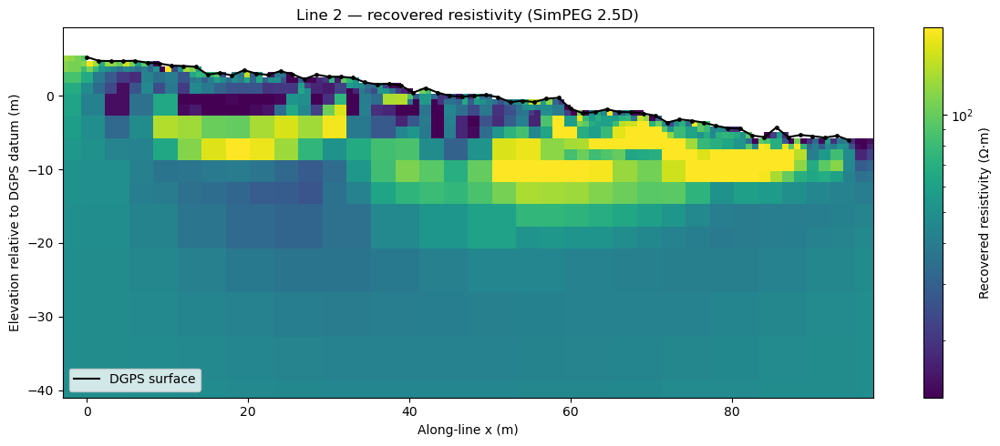

Line 2: normalized residual RMS=1.967; chi²/N=3.868 (based on assumed errors)


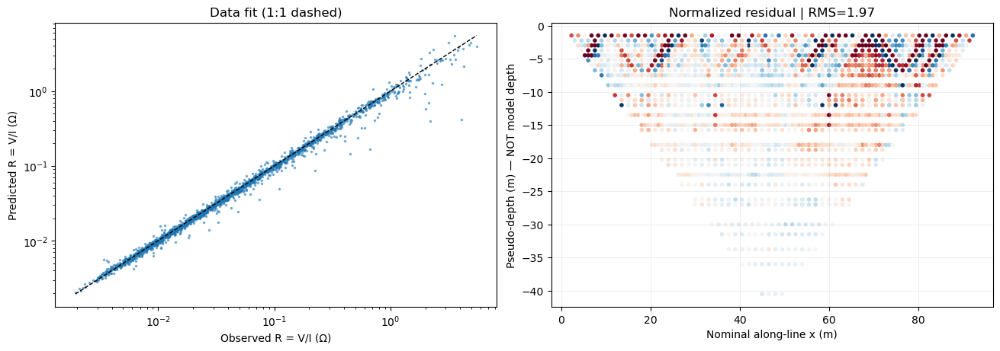

In [15]:
if RUN_LINE2:
    print("\n--- Inverting Dipole–Dipole Line 2 ---")
    solve_line(2)
    summaries[2] = report_line(2)
else:
    print("Line 2 has not been inverted yet. Change RUN_LINE2 to True in Settings first.")


## 12. Interpretation checklist

1. Compare each inverted model with its observed/predicted resistance and normalized residuals. A striking colored feature is not automatically real if the model does not explain the observations.
2. Inspect questionable measurements in the original ABEM export. No reciprocal error information was supplied: the assumed 5% + floor uncertainties affect both the fit and what is considered significant.
3. Verify the ABEM header's `x_location_type`: `1` means true horizontal x, `2` means distance measured along the surface. If it is `2`, improve x geometry using the DGPS horizontal distances before reporting precise depth/size.
4. Re-invert with different starting resistivities, smoothness strengths, assumed uncertainties and mesh refinement; compare anomaly robustness. A high- or low-resistivity body **does not prove an air-filled void**.
5. Evaluate whether the estimated 6–10 m tunnel depth lies within sufficient survey sensitivity; sensitivity/depth-of-investigation testing is a future step, **not** guaranteed by a 35 m-deep plot.
6. These are independent **2.5D** line inversions. A tunnel intersecting at an oblique angle, curved acquisition lines, and three-dimensional out-of-plane effects can bias results.


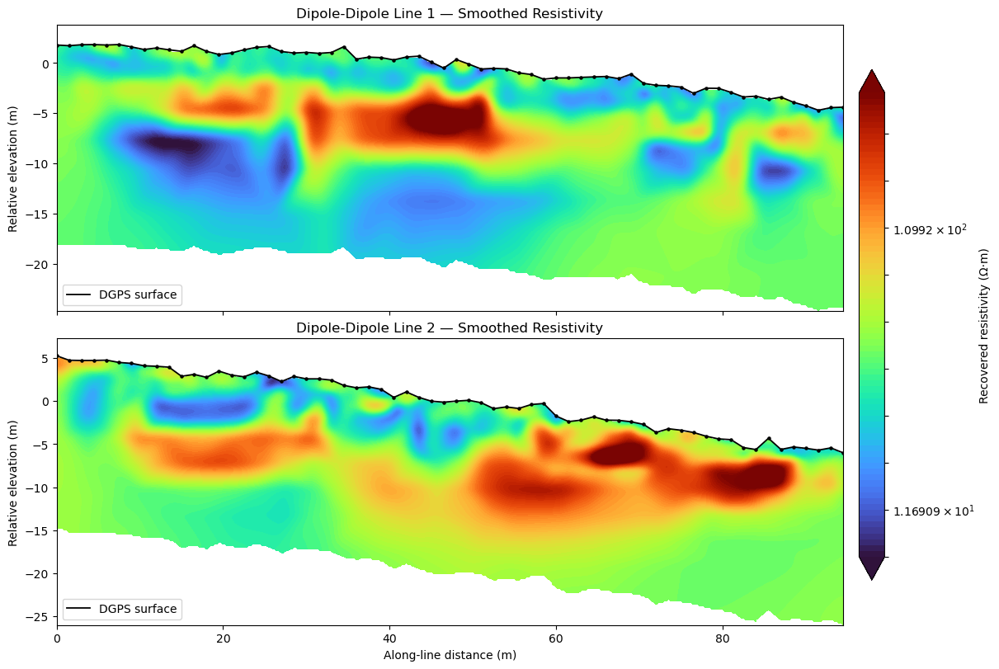

In [19]:

# --------------------------------------------
# PLOT SETTINGS
# --------------------------------------------
DISPLAY_DEPTH_M = 20       # Show upper 20 m below local ground
SMOOTH_X_M = 0.7           # Horizontal display smoothing
SMOOTH_Z_M = 0.4           # Vertical display smoothing
GRID_DX_M = 0.25           # Horizontal plotting resolution
GRID_DZ_M = 0.20           # Vertical plotting resolution
CMAP = "turbo"             # Blue = conductive, red = resistive

# --------------------------------------------
# COMMON COLOR SCALE
# --------------------------------------------
rho_for_scale = []

for line in (1, 2):
    out = results[line]
    topo = geometry[line]["topo"]
    centers = out["mesh"].cell_centers[out["active"]]
    rho = np.exp(-out["m_recovered"])

    surface = np.interp(
        centers[:, 0], topo[:, 0], topo[:, 1]
    )
    depth = surface - centers[:, 1]

    use = (
        (centers[:, 0] >= topo[:, 0].min()) &
        (centers[:, 0] <= topo[:, 0].max()) &
        (depth >= 0) &
        (depth <= DISPLAY_DEPTH_M)
    )
    rho_for_scale.append(rho[use])

all_rho = np.concatenate(rho_for_scale)
vmin, vmax = np.percentile(all_rho, [2, 98])

norm = LogNorm(
    vmin=max(vmin, 1e-3),
    vmax=max(vmax, vmin * 1.01)
)

levels = np.geomspace(norm.vmin, norm.vmax, 80)

# --------------------------------------------
# SMOOTH INTERPOLATION FUNCTION
# --------------------------------------------
def smooth_section(line):
    out = results[line]
    topo = geometry[line]["topo"]

    centers = out["mesh"].cell_centers[out["active"]]
    log_rho = -out["m_recovered"] / np.log(10.0)

    x = np.arange(
        topo[:, 0].min(),
        topo[:, 0].max() + GRID_DX_M,
        GRID_DX_M
    )
    z = np.arange(
        topo[:, 1].min() - DISPLAY_DEPTH_M,
        topo[:, 1].max() + 2 + GRID_DZ_M,
        GRID_DZ_M
    )

    X, Z = np.meshgrid(x, z)

    # Interpolate log-resistivity onto a regular grid.
    log_grid = griddata(
        centers, log_rho, (X, Z), method="linear"
    )

    # Fill cells outside the interpolation hull.
    missing = ~np.isfinite(log_grid)
    if missing.any():
        log_grid[missing] = griddata(
            centers,
            log_rho,
            (X[missing], Z[missing]),
            method="nearest"
        )

    # Mask everything above or beyond the chosen
    # depth below the measured DGPS surface.
    surface = np.interp(
        x, topo[:, 0], topo[:, 1]
    )[None, :]

    inside = (
        (Z <= surface) &
        (Z >= surface - DISPLAY_DEPTH_M)
    )

    # Apply light Gaussian smoothing in log-resistivity.
    sigma = (
        SMOOTH_Z_M / GRID_DZ_M,
        SMOOTH_X_M / GRID_DX_M
    )

    weights = gaussian_filter(
        inside.astype(float), sigma=sigma
    )
    smoothed_log = gaussian_filter(
        np.where(inside, log_grid, 0), sigma=sigma
    )
    smoothed_log /= np.maximum(weights, 1e-8)

    rho_plot = np.ma.array(
        10 ** smoothed_log,
        mask=~inside
    )

    return X, Z, rho_plot

# --------------------------------------------
# PLOT BOTH INVERTED SECTIONS
# --------------------------------------------
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8),
    sharex=True,
    constrained_layout=True
)

for line, ax in zip((1, 2), axes):

    X, Z, rho_plot = smooth_section(line)

    cf = ax.contourf(
        X, Z, rho_plot,
        levels=levels,
        norm=norm,
        cmap=CMAP,
        extend="both"
    )

    topo = geometry[line]["topo"]

    ax.plot(
        topo[:, 0], topo[:, 1],
        "k-", lw=1.3,
        label="DGPS surface"
    )
    ax.scatter(
        topo[:, 0], topo[:, 1],
        s=5, c="k"
    )

    ax.set(
        ylabel="Relative elevation (m)",
        title=f"Dipole-Dipole Line {line} — Smoothed Resistivity",
        ylim=(
            topo[:, 1].min() - DISPLAY_DEPTH_M,
            topo[:, 1].max() + 2
        )
    )

    ax.set_facecolor("white")
    ax.legend(loc="lower left")

axes[-1].set_xlabel("Along-line distance (m)")

fig.colorbar(
    cf, ax=axes,
    label="Recovered resistivity (Ω·m)",
    pad=0.02,
    shrink=0.85
)

plt.show()


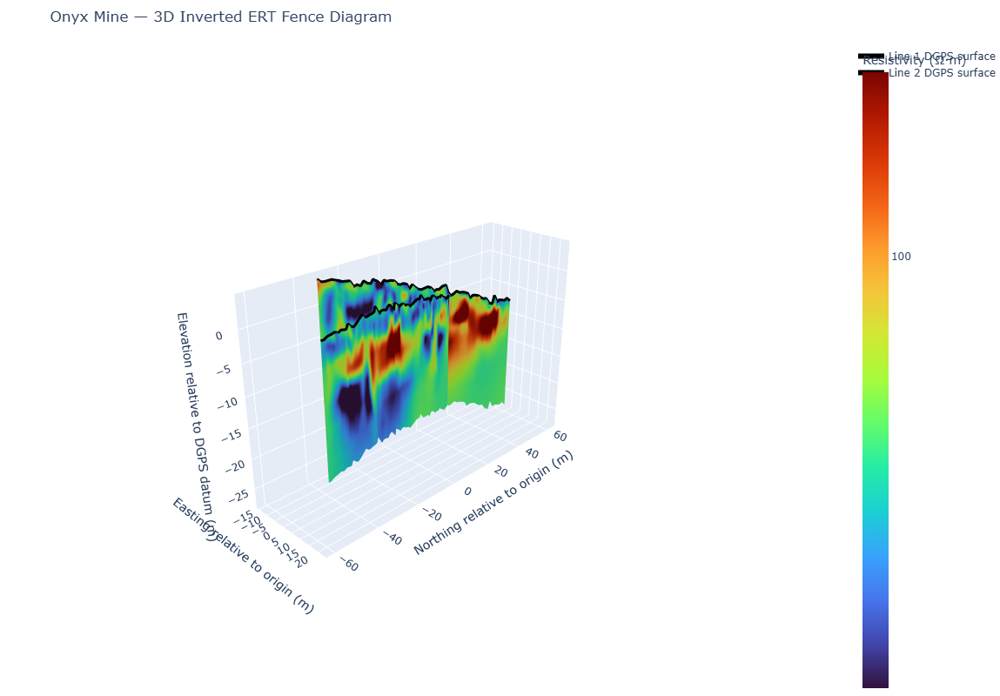

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\molly\\work\\Senior-Design-Geophysical-Characterization-of-Historic-Mine-Tunnels\\working_notebooks\\ERT\\ERT_outputs\\DipoleDipole_Inversions\\Onyx_ERT_3D_Fence.html'

In [23]:

# --------------------------------------------
# SETTINGS
# --------------------------------------------
DEPTH_M = 20.0       # Depth below local surface (m)
NX = 260             # Horizontal display resolution
NZ = 101             # Vertical display resolution

SMOOTH_X_M = 0.65
SMOOTH_Z_M = 0.35

# Geographic coordinates -> UTM Zone 13N
transformer = Transformer.from_crs(
    "EPSG:4326", "EPSG:32613", always_xy=True
)

# --------------------------------------------
# PREPARE DGPS SURVEY TRACKS
# --------------------------------------------
tracks = {}

for line in (1, 2):
    p = profiles[line].sort_values("distance_m")

    e, n = transformer.transform(
        p["Longitude"].to_numpy(),
        p["Latitude"].to_numpy()
    )

    tracks[line] = {
        "x": p["distance_m"].to_numpy(dtype=float),
        "e": np.asarray(e),
        "n": np.asarray(n),
        "h": p["elevation_m"].to_numpy(dtype=float)
    }

# One common coordinate origin and elevation datum
E0 = np.mean(np.r_[tracks[1]["e"], tracks[2]["e"]])
N0 = np.mean(np.r_[tracks[1]["n"], tracks[2]["n"]])
Z0 = np.median(np.r_[tracks[1]["h"], tracks[2]["h"]])

# --------------------------------------------
# CREATE A VERTICAL RESISTIVITY CURTAIN
# --------------------------------------------
def make_curtain(line):
    t = tracks[line]

    x = np.linspace(t["x"].min(), t["x"].max(), NX)
    depth = np.linspace(0, DEPTH_M, NZ)

    X, D = np.meshgrid(x, depth)

    # Position the section along the measured DGPS path.
    east = np.interp(x, t["x"], t["e"]) - E0
    north = np.interp(x, t["x"], t["n"]) - N0
    surface = np.interp(x, t["x"], t["h"])

    # A vertical section following actual ground elevation
    Z = surface[None, :] - D - Z0

    # Retrieve the inverted SimPEG resistivity model
    out = results[line]
    cells = out["mesh"].cell_centers[out["active"]]

    # Model parameter is natural logarithm of conductivity
    log_rho = -out["m_recovered"] / np.log(10.0)

    # Transform elevation back to each inversion's datum
    query_z = Z + Z0 - geometry[line]["datum"]

    # Restrict interpolation to nearby model cells
    use = (
        (cells[:, 0] >= x.min() - 5) &
        (cells[:, 0] <= x.max() + 5) &
        (cells[:, 1] >= query_z.min() - 5) &
        (cells[:, 1] <= query_z.max() + 5)
    )

    if use.sum() < 10:
        raise ValueError(
            f"Line {line}: insufficient model cells"
        )

    points = cells[use]
    values = log_rho[use]

    log_grid = griddata(
        points, values, (X, query_z),
        method="linear"
    )

    missing = ~np.isfinite(log_grid)

    if missing.any():
        log_grid[missing] = griddata(
            points, values,
            (X[missing], query_z[missing]),
            method="nearest"
        )

    # Light display-only smoothing
    dx = (x.max() - x.min()) / (NX - 1)
    dz = DEPTH_M / (NZ - 1)

    log_grid = gaussian_filter(
        log_grid,
        sigma=(SMOOTH_Z_M / dz, SMOOTH_X_M / dx)
    )

    return {
        "E": np.broadcast_to(east, X.shape),
        "N": np.broadcast_to(north, X.shape),
        "Z": Z,
        "logrho": log_grid,
        "depth": D
    }


sections = {
    line: make_curtain(line) for line in (1, 2)
}

# Common logarithmic color scale
all_log = np.concatenate([
    sections[i]["logrho"].ravel() for i in (1, 2)
])

cmin, cmax = np.percentile(all_log, [2, 98])
if cmax <= cmin:
    cmax = cmin + 0.1

# --------------------------------------------
# CALCULATE TRUE DGPS LINE INTERSECTION
# --------------------------------------------
def cross2(a, b):
    return a[0] * b[1] - a[1] * b[0]


def find_intersection(a, b):
    P = np.c_[a["e"], a["n"]]
    Q = np.c_[b["e"], b["n"]]

    for i in range(len(P) - 1):
        p = P[i]
        r = P[i + 1] - P[i]

        for j in range(len(Q) - 1):
            q = Q[j]
            s = Q[j + 1] - Q[j]

            denominator = cross2(r, s)

            if abs(denominator) < 1e-8:
                continue

            t = cross2(q - p, s) / denominator
            u = cross2(q - p, r) / denominator

            if 0 <= t <= 1 and 0 <= u <= 1:
                xy = p + t * r

                x1 = a["x"][i] + t * (
                    a["x"][i + 1] - a["x"][i]
                )
                x2 = b["x"][j] + u * (
                    b["x"][j + 1] - b["x"][j]
                )

                return xy, x1, x2

    return None


# --------------------------------------------
# BUILD INTERACTIVE 3D FIGURE
# --------------------------------------------
fig = go.Figure()

ticks = np.arange(np.ceil(cmin), np.floor(cmax) + 1)

for line in (1, 2):
    s = sections[line]

    fig.add_trace(go.Surface(
        x=s["E"],
        y=s["N"],
        z=s["Z"],
        surfacecolor=s["logrho"],

        customdata=np.stack([
            10 ** s["logrho"],
            s["depth"]
        ], axis=-1),

        colorscale="Turbo",
        cmin=cmin,
        cmax=cmax,
        opacity=1,

        showscale=(line == 2),
        colorbar=dict(
            title="Resistivity (Ω·m)",
            tickvals=ticks,
            ticktext=[f"{10**j:g}" for j in ticks]
        ),

        name=f"Line {line}",

        hovertemplate=(
            f"Line {line}"
            "<br>East: %{x:.1f} m"
            "<br>North: %{y:.1f} m"
            "<br>Relative elevation: %{z:.1f} m"
            "<br>Depth: %{customdata[1]:.1f} m"
            "<br>Resistivity: %{customdata[0]:.1f} Ω·m"
            "<extra></extra>"
        )
    ))

    # DGPS topographic surface line
    t = tracks[line]

    fig.add_trace(go.Scatter3d(
        x=t["e"] - E0,
        y=t["n"] - N0,
        z=t["h"] - Z0,
        mode="lines",
        line=dict(color="black", width=6),
        name=f"Line {line} DGPS surface"
    ))

# Mark surveyed line intersection
intersection = find_intersection(tracks[1], tracks[2])

if intersection is not None:
    xy, x1, x2 = intersection

    h1 = np.interp(
        x1, tracks[1]["x"], tracks[1]["h"]
    )
    h2 = np.interp(
        x2, tracks[2]["x"], tracks[2]["h"]
    )

    fig.add_trace(go.Scatter3d(
        x=[xy[0] - E0],
        y=[xy[1] - N0],
        z=[0.5 * (h1 + h2) - Z0],
        mode="markers",
        marker=dict(
            color="black",
            size=7,
            symbol="diamond"
        ),
        name="DGPS intersection",
        hovertemplate=(
            f"DGPS intersection"
            f"<br>Line 1 distance: {x1:.1f} m"
            f"<br>Line 2 distance: {x2:.1f} m"
            "<extra></extra>"
        )
    ))

    print(f"Intersection: Line 1 = {x1:.2f} m")
    print(f"Intersection: Line 2 = {x2:.2f} m")
    print(
        f"DGPS height difference at crossing: "
        f"{abs(h1-h2):.2f} m"
    )

else:
    print(
        "WARNING: DGPS polylines do not mathematically "
        "intersect. Check survey alignment."
    )

# --------------------------------------------
# CAMERA AND DISPLAY
# --------------------------------------------
range_e = np.ptp(np.r_[
    tracks[1]["e"], tracks[2]["e"]
])
range_n = np.ptp(np.r_[
    tracks[1]["n"], tracks[2]["n"]
])
span = max(range_e, range_n)

fig.update_layout(
    title="Onyx Mine — 3D Inverted ERT Fence Diagram",
    height=800,

    scene=dict(
        xaxis_title="Easting relative to origin (m)",
        yaxis_title="Northing relative to origin (m)",
        zaxis_title="Elevation relative to DGPS datum (m)",

        aspectmode="manual",
        aspectratio=dict(
            x=range_e / span,
            y=range_n / span,
            z=0.65
        ),

        camera=dict(
            eye=dict(x=1.5, y=-1.5, z=1.0)
        )
    ),

    margin=dict(l=0, r=0, t=50, b=0)
)

# --------------------------------------------
# SHOW AND SAVE
# --------------------------------------------
fig.show()

fig.write_html(
    str(INVERSION_DIR / "Onyx_ERT_3D_Fence.html"),
    include_plotlyjs=True
)
